In [1]:
from pathlib import Path
import time
import joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline, FeatureUnion

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

LABELS = ["Low", "Moderate", "High"]
RANDOM_STATE = 26

In [2]:
train_df = pd.read_parquet(ROOT / "data/splits/train.parquet")
val_df = pd.read_parquet(ROOT / "data/splits/validation.parquet")
test_df = pd.read_parquet(ROOT / "data/splits/test.parquet")

print("Train:", train_df.shape)
print("Validation:", val_df.shape)
print("Test:", test_df.shape)

display(train_df.head())

Train: (270, 11)
Validation: (57, 11)
Test: (58, 11)


,review_id,paper_id,label,title_en,abstract_en,title_kk,abstract_kk,normalized_title_en,normalized_title_kk,split_group_id,split
0,0,p_3faf61b5e948e454,Moderate,The Significance of Using Gamification Element...,Gamification elements are used in various fiel...,Геймификация элементтерін оқу-тәрбие үрдісінде...,Геймификация элементтері әртүрлі салаларда қол...,the significance of using gamification element...,геймификация элементтерін оқу-тәрбие үрдісінде...,g_3faf61b5e948e454,train
1,1,p_3faf61b5e948e454,Moderate,The Significance of Using Gamification Element...,Gamification elements are used in various fiel...,Геймификация элементтерін оқу-тәрбие үрдісінде...,Геймификация элементтері әртүрлі салаларда қол...,the significance of using gamification element...,геймификация элементтерін оқу-тәрбие үрдісінде...,g_3faf61b5e948e454,train
2,3,p_464fa19e2ada412a,Moderate,Application of Deep Learning in the Problem of...,"In recent years, deep learning has become a po...",Суретті реставрациялау мәселесінде тереңдетіп ...,"Соңғы жылдары терең оқыту шуды жою, супер ажыр...",application of deep learning in the problem of...,суретті реставрациялау мәселесінде тереңдетіп ...,g_464fa19e2ada412a,train
3,4,p_464fa19e2ada412a,Moderate,Application of Deep Learning in the Problem of...,"In recent years, deep learning has become a po...",Суретті реставрациялау мәселесінде тереңдетіп ...,"Соңғы жылдары терең оқыту шуды жою, супер ажыр...",application of deep learning in the problem of...,суретті реставрациялау мәселесінде тереңдетіп ...,g_464fa19e2ada412a,train
4,5,p_fb8a646fbe80d8ff,Moderate,Improving the Classification Result of Rice Va...,An accurate identification of rice grain is cr...,"Градиентті күшейту әдістерін қолдана отырып, к...",Күріш дәндерін дәл сәйкестендіру күріш сорттар...,improving the classification result of rice va...,"градиентті күшейту әдістерін қолдана отырып, к...",g_fb8a646fbe80d8ff,train


In [3]:
def prepare_text(df, language):
    title_col = f"title_{language}"
    abstract_col = f"abstract_{language}"

    result = df.copy()

    result["text"] = (
        result[title_col].fillna("").astype(str)
        + " [SEP] "
        + result[abstract_col].fillna("").astype(str)
    )

    return result


def expand_multilingual(df):
    en = prepare_text(df, "en")
    en["language"] = "English"

    kk = prepare_text(df, "kk")
    kk["language"] = "Kazakh"

    return pd.concat([en, kk], ignore_index=True)


train_en = prepare_text(train_df, "en")
val_en = prepare_text(val_df, "en")
test_en = prepare_text(test_df, "en")

train_kk = prepare_text(train_df, "kk")
val_kk = prepare_text(val_df, "kk")
test_kk = prepare_text(test_df, "kk")

train_multi = expand_multilingual(train_df)
val_multi = expand_multilingual(val_df)
test_multi = expand_multilingual(test_df)

In [4]:
for name, df in {
    "Train EN": train_en,
    "Validation EN": val_en,
    "Test EN": test_en,
    "Train KK": train_kk,
    "Train Multilingual": train_multi
}.items():
    print(f"\n{name}")
    print(df["label"].value_counts())


Train EN
label
Moderate    168
High         71
Low          31
Name: count, dtype: int64

Validation EN
label
Moderate    35
High        16
Low          6
Name: count, dtype: int64

Test EN
label
Moderate    35
High        16
Low          7
Name: count, dtype: int64

Train KK
label
Moderate    168
High         71
Low          31
Name: count, dtype: int64

Train Multilingual
label
Moderate    336
High        142
Low          62
Name: count, dtype: int64


In [6]:
def build_pipeline(feature_type, C=1.0, class_weight=None):

    if feature_type == "word":
        features = TfidfVectorizer(
            analyzer="word",
            ngram_range=(1, 2),
            min_df=1,
            sublinear_tf=True,
            max_features=50000
        )

    elif feature_type == "char":
        features = TfidfVectorizer(
            analyzer="char_wb",
            ngram_range=(3, 5),
            min_df=1,
            sublinear_tf=True,
            max_features=100000
        )

    elif feature_type == "combined":
        features = FeatureUnion([
            ("word", TfidfVectorizer(
                analyzer="word",
                ngram_range=(1, 2),
                min_df=1,
                sublinear_tf=True,
                max_features=50000
            )),
            ("char", TfidfVectorizer(
                analyzer="char_wb",
                ngram_range=(3, 5),
                min_df=1,
                sublinear_tf=True,
                max_features=100000
            ))
        ])

    else:
        raise ValueError("Unknown feature type")

    return Pipeline([
        ("tfidf", features),
        ("classifier", LogisticRegression(
            C=C,
            class_weight=class_weight,
            max_iter=3000,
            random_state=RANDOM_STATE
        ))
    ])

In [7]:
def evaluate_model(model, X, y):
    predictions = model.predict(X)

    return {
        "accuracy": accuracy_score(y, predictions),
        "precision_macro": precision_score(
            y, predictions, average="macro", zero_division=0
        ),
        "recall_macro": recall_score(
            y, predictions, average="macro", zero_division=0
        ),
        "macro_f1": f1_score(
            y, predictions, average="macro", zero_division=0
        ),
        "weighted_f1": f1_score(
            y, predictions, average="weighted", zero_division=0
        )
    }

In [8]:
from itertools import product

def tune_model(train_data, val_data, feature_type):

    X_train = train_data["text"]
    y_train = train_data["label"]

    X_val = val_data["text"]
    y_val = val_data["label"]

    best_score = -1
    best_params = None
    best_model = None

    for C, class_weight in product(
        [0.1, 1.0, 10.0],
        [None, "balanced"]
    ):
        model = build_pipeline(
            feature_type,
            C=C,
            class_weight=class_weight
        )

        model.fit(X_train, y_train)

        metrics = evaluate_model(model, X_val, y_val)

        print(
            f"C={C}, class_weight={class_weight}, "
            f"Macro F1={metrics['macro_f1']:.4f}"
        )

        if metrics["macro_f1"] > best_score:
            best_score = metrics["macro_f1"]
            best_params = {
                "C": C,
                "class_weight": class_weight
            }
            best_model = model

    return best_model, best_params, best_score

In [11]:
datasets = {
    "english": (train_en, val_en, test_en),
    "kazakh": (train_kk, val_kk, test_kk),
    "multilingual": (train_multi, val_multi, test_multi)
}

feature_types = ["word", "char", "combined"]

results = []

# Create model directory if it does not exist
model_dir = ROOT / "models" / "tfidf"
model_dir.mkdir(parents=True, exist_ok=True)

for language, (train_data, val_data, test_data) in datasets.items():

    for feature_type in feature_types:

        print("\n" + "=" * 60)
        print(f"Experiment: {language} | {feature_type}")

        best_model, best_params, val_score = tune_model(
            train_data,
            val_data,
            feature_type
        )

        # Refit using train + validation after model selection.
        train_val = pd.concat(
            [train_data, val_data],
            ignore_index=True
        )

        final_model = build_pipeline(
            feature_type,
            C=best_params["C"],
            class_weight=best_params["class_weight"]
        )

        final_model.fit(
            train_val["text"],
            train_val["label"]
        )

        test_metrics = evaluate_model(
            final_model,
            test_data["text"],
            test_data["label"]
        )

        results.append({
            "language": language,
            "feature_type": feature_type,
            "best_params": str(best_params),
            "validation_macro_f1": val_score,
            **test_metrics
        })

        model_path = model_dir / f"{language}_{feature_type}.joblib"

        joblib.dump(final_model, model_path)

        print(f"Model saved: {model_path}")

results_df = pd.DataFrame(results)
display(results_df.sort_values("macro_f1", ascending=False))


Experiment: english | word
C=0.1, class_weight=None, Macro F1=0.2536
C=0.1, class_weight=balanced, Macro F1=0.2933
C=1.0, class_weight=None, Macro F1=0.2536
C=1.0, class_weight=balanced, Macro F1=0.2693
C=10.0, class_weight=None, Macro F1=0.2536
C=10.0, class_weight=balanced, Macro F1=0.2693
Model saved: C:\Users\User\PycharmProjects\Peer_Review_Score_Prediction_from_Kazakh_and_English_Abstracts\models\tfidf\english_word.joblib

Experiment: english | char
C=0.1, class_weight=None, Macro F1=0.2536
C=0.1, class_weight=balanced, Macro F1=0.4289
C=1.0, class_weight=None, Macro F1=0.2536
C=1.0, class_weight=balanced, Macro F1=0.3607
C=10.0, class_weight=None, Macro F1=0.2889
C=10.0, class_weight=balanced, Macro F1=0.2564
Model saved: C:\Users\User\PycharmProjects\Peer_Review_Score_Prediction_from_Kazakh_and_English_Abstracts\models\tfidf\english_char.joblib

Experiment: english | combined
C=0.1, class_weight=None, Macro F1=0.2536
C=0.1, class_weight=balanced, Macro F1=0.2838
C=1.0, class_w

,language,feature_type,best_params,validation_macro_f1,accuracy,precision_macro,recall_macro,macro_f1,weighted_f1
4,kazakh,char,"{'C': 0.1, 'class_weight': 'balanced'}",0.413889,0.534483,0.491667,0.401190,0.412407,0.516475
7,multilingual,char,"{'C': 0.1, 'class_weight': 'balanced'}",0.408041,0.482759,0.341813,0.342262,0.340784,0.471034
1,english,char,"{'C': 0.1, 'class_weight': 'balanced'}",0.428854,0.448276,0.338889,0.330952,0.331637,0.449986
8,multilingual,combined,"{'C': 0.1, 'class_weight': 'balanced'}",0.285357,0.517241,0.261111,0.308333,0.276182,0.449586
0,english,word,"{'C': 0.1, 'class_weight': 'balanced'}",0.293265,0.517241,0.235000,0.297024,0.255229,0.434753
6,multilingual,word,"{'C': 1.0, 'class_weight': 'balanced'}",0.279009,0.551724,0.231447,0.310417,0.254509,0.445150
2,english,combined,"{'C': 10.0, 'class_weight': None}",0.288889,0.603448,0.201149,0.333333,0.250896,0.454208
3,kazakh,word,"{'C': 1.0, 'class_weight': 'balanced'}",0.288889,0.586207,0.202381,0.323810,0.249084,0.450928
5,kazakh,combined,"{'C': 10.0, 'class_weight': 'balanced'}",0.288889,0.586207,0.202381,0.323810,0.249084,0.450928



english_word | english
              precision    recall  f1-score   support

         Low       0.00      0.00      0.00         7
    Moderate       0.58      0.83      0.68        35
        High       0.12      0.06      0.08        16

    accuracy                           0.52        58
   macro avg       0.23      0.30      0.26        58
weighted avg       0.38      0.52      0.43        58



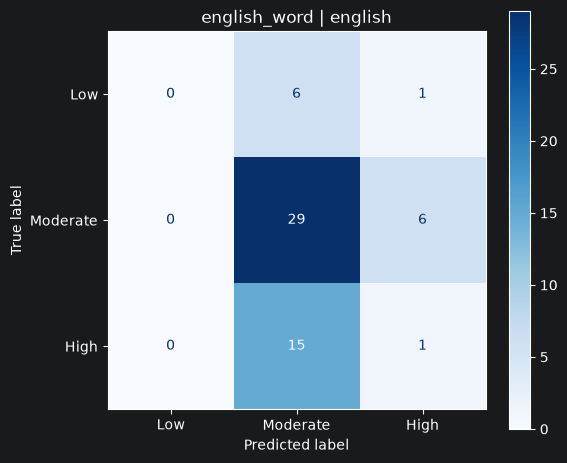


kazakh_word | kazakh
              precision    recall  f1-score   support

         Low       0.00      0.00      0.00         7
    Moderate       0.61      0.97      0.75        35
        High       0.00      0.00      0.00        16

    accuracy                           0.59        58
   macro avg       0.20      0.32      0.25        58
weighted avg       0.37      0.59      0.45        58



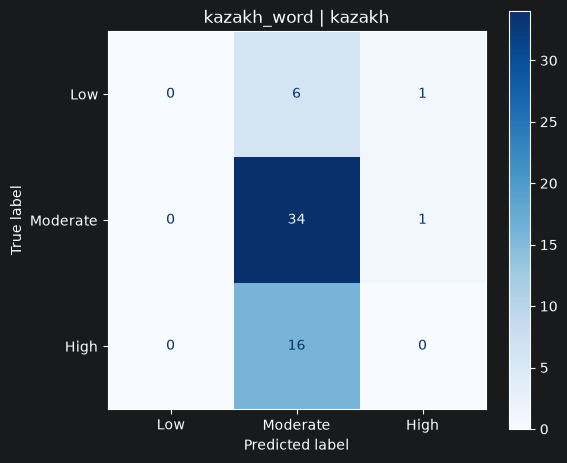


english_char | english
              precision    recall  f1-score   support

         Low       0.10      0.14      0.12         7
    Moderate       0.58      0.60      0.59        35
        High       0.33      0.25      0.29        16

    accuracy                           0.45        58
   macro avg       0.34      0.33      0.33        58
weighted avg       0.46      0.45      0.45        58



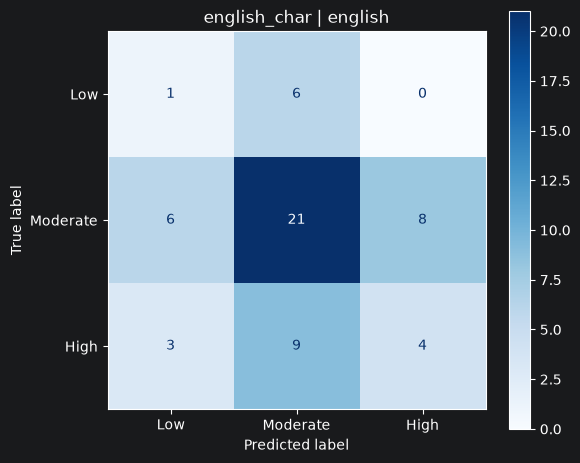


kazakh_char | kazakh
              precision    recall  f1-score   support

         Low       0.50      0.14      0.22         7
    Moderate       0.60      0.69      0.64        35
        High       0.38      0.38      0.38        16

    accuracy                           0.53        58
   macro avg       0.49      0.40      0.41        58
weighted avg       0.53      0.53      0.52        58



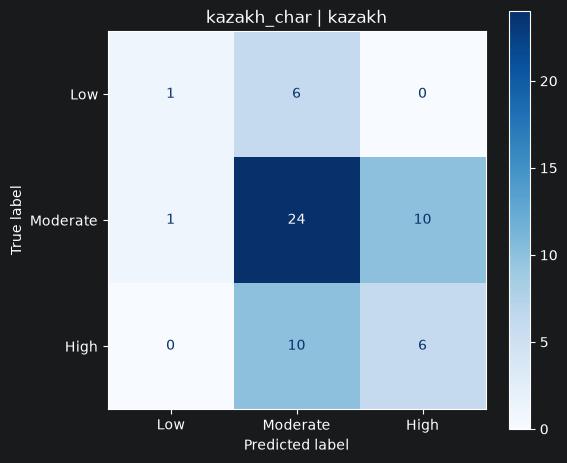


english_combined | english
              precision    recall  f1-score   support

         Low       0.00      0.00      0.00         7
    Moderate       0.60      1.00      0.75        35
        High       0.00      0.00      0.00        16

    accuracy                           0.60        58
   macro avg       0.20      0.33      0.25        58
weighted avg       0.36      0.60      0.45        58



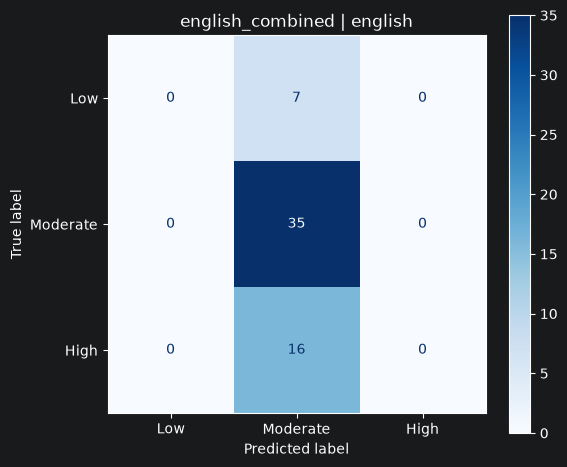


kazakh_combined | kazakh
              precision    recall  f1-score   support

         Low       0.00      0.00      0.00         7
    Moderate       0.61      0.97      0.75        35
        High       0.00      0.00      0.00        16

    accuracy                           0.59        58
   macro avg       0.20      0.32      0.25        58
weighted avg       0.37      0.59      0.45        58



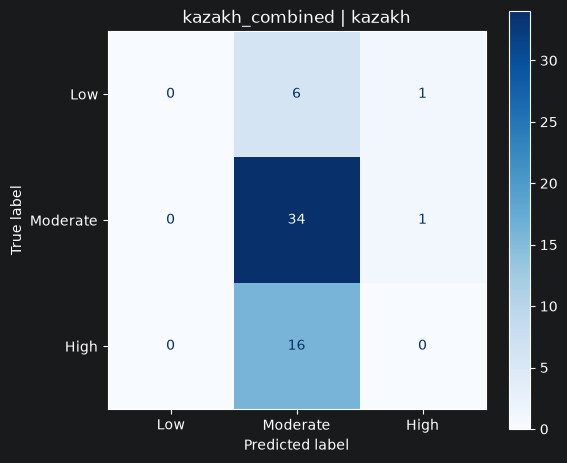


multilingual_word | combined
              precision    recall  f1-score   support

         Low       0.00      0.00      0.00        14
    Moderate       0.59      0.90      0.72        70
        High       0.10      0.03      0.05        32

    accuracy                           0.55       116
   macro avg       0.23      0.31      0.25       116
weighted avg       0.39      0.55      0.45       116



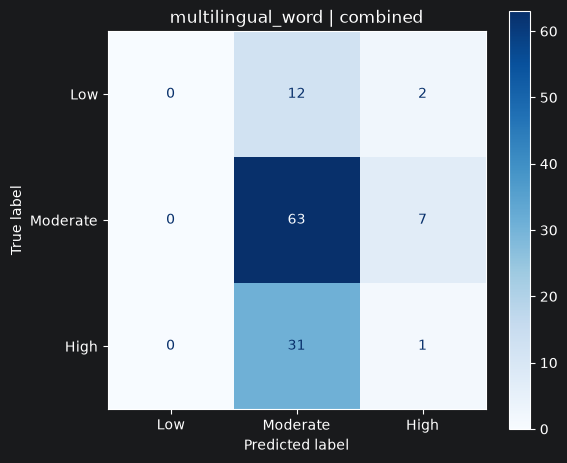


multilingual_word | english
              precision    recall  f1-score   support

         Low       0.00      0.00      0.00         7
    Moderate       0.58      0.83      0.68        35
        High       0.12      0.06      0.08        16

    accuracy                           0.52        58
   macro avg       0.23      0.30      0.26        58
weighted avg       0.38      0.52      0.43        58



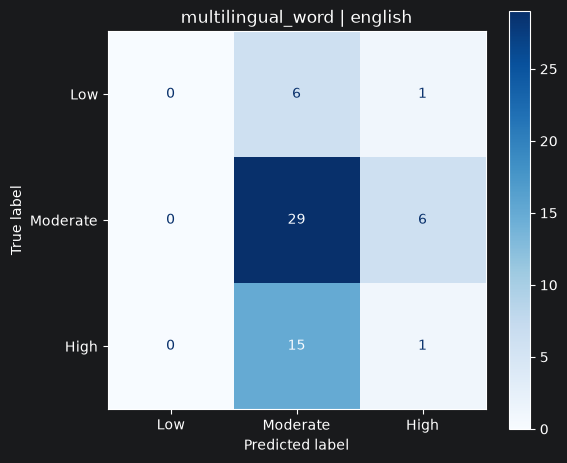


multilingual_word | kazakh
              precision    recall  f1-score   support

         Low       0.00      0.00      0.00         7
    Moderate       0.61      0.97      0.75        35
        High       0.00      0.00      0.00        16

    accuracy                           0.59        58
   macro avg       0.20      0.32      0.25        58
weighted avg       0.37      0.59      0.45        58



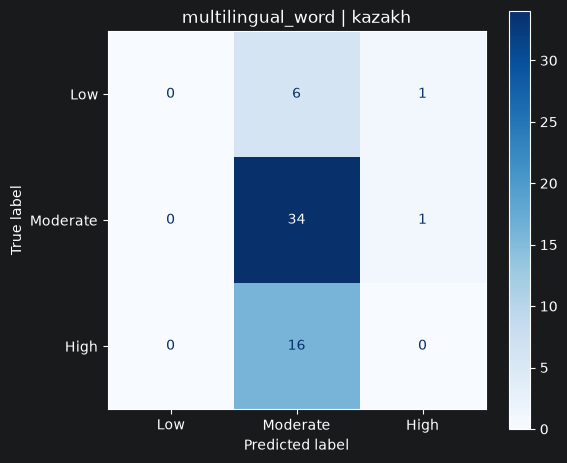


multilingual_char | combined
              precision    recall  f1-score   support

         Low       0.10      0.07      0.08        14
    Moderate       0.59      0.64      0.62        70
        High       0.33      0.31      0.32        32

    accuracy                           0.48       116
   macro avg       0.34      0.34      0.34       116
weighted avg       0.46      0.48      0.47       116



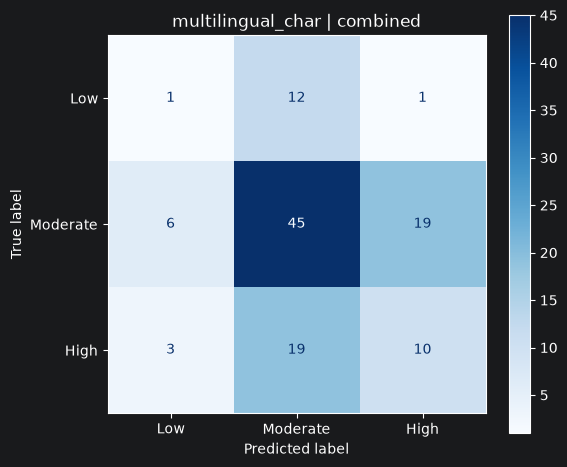


multilingual_char | english
              precision    recall  f1-score   support

         Low       0.10      0.14      0.12         7
    Moderate       0.58      0.60      0.59        35
        High       0.33      0.25      0.29        16

    accuracy                           0.45        58
   macro avg       0.34      0.33      0.33        58
weighted avg       0.46      0.45      0.45        58



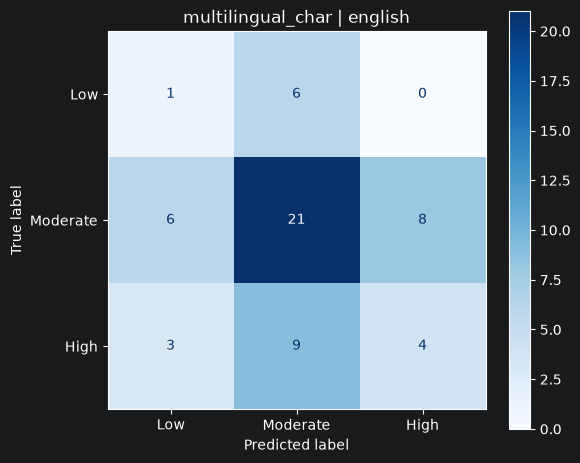


multilingual_char | kazakh
              precision    recall  f1-score   support

         Low       0.00      0.00      0.00         7
    Moderate       0.60      0.69      0.64        35
        High       0.33      0.38      0.35        16

    accuracy                           0.52        58
   macro avg       0.31      0.35      0.33        58
weighted avg       0.45      0.52      0.48        58



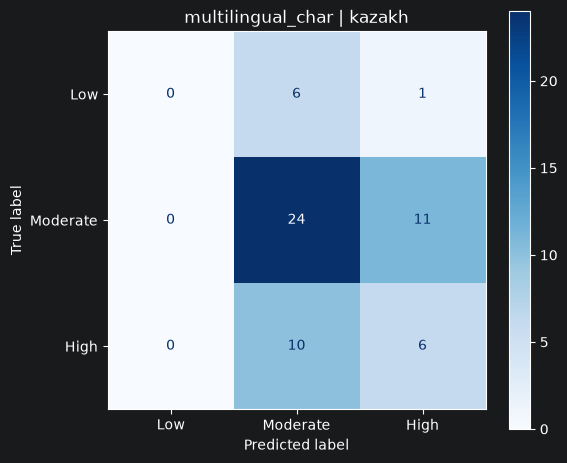


multilingual_combined | combined
              precision    recall  f1-score   support

         Low       0.00      0.00      0.00        14
    Moderate       0.58      0.80      0.67        70
        High       0.20      0.12      0.15        32

    accuracy                           0.52       116
   macro avg       0.26      0.31      0.28       116
weighted avg       0.41      0.52      0.45       116



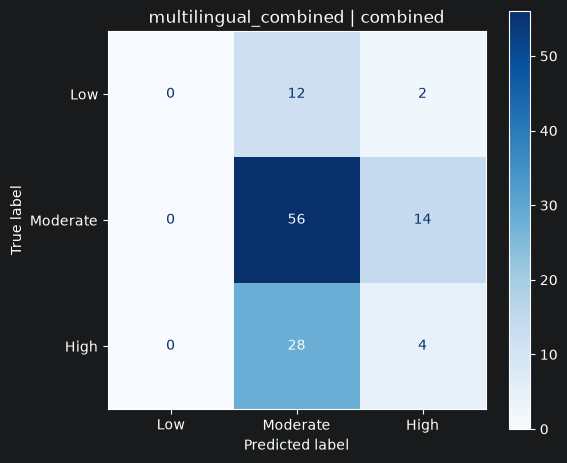


multilingual_combined | english
              precision    recall  f1-score   support

         Low       0.00      0.00      0.00         7
    Moderate       0.60      0.86      0.71        35
        High       0.25      0.12      0.17        16

    accuracy                           0.55        58
   macro avg       0.28      0.33      0.29        58
weighted avg       0.43      0.55      0.47        58



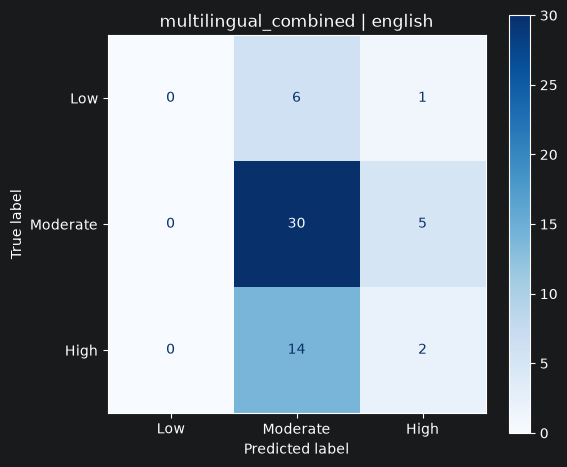


multilingual_combined | kazakh
              precision    recall  f1-score   support

         Low       0.00      0.00      0.00         7
    Moderate       0.57      0.74      0.64        35
        High       0.17      0.12      0.14        16

    accuracy                           0.48        58
   macro avg       0.24      0.29      0.26        58
weighted avg       0.39      0.48      0.43        58



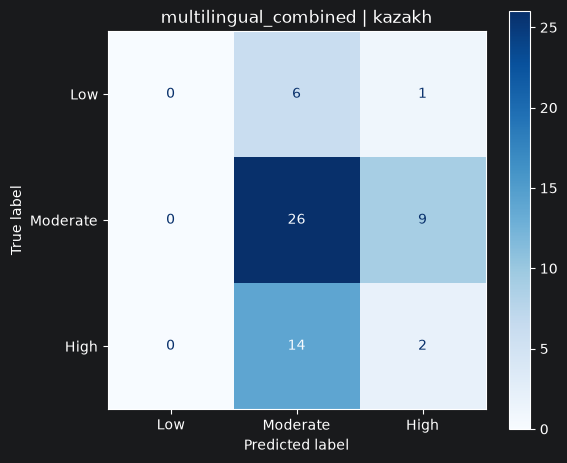

,experiment,language,accuracy,precision_macro,recall_macro,macro_f1,weighted_f1
3,kazakh_char,kazakh,0.534483,0.491667,0.401190,0.412407,0.516475
9,multilingual_char,combined,0.482759,0.341813,0.342262,0.340784,0.471034
2,english_char,english,0.448276,0.338889,0.330952,0.331637,0.449986
10,multilingual_char,english,0.448276,0.338889,0.330952,0.331637,0.449986
11,multilingual_char,kazakh,0.517241,0.311111,0.353571,0.330980,0.483570
13,multilingual_combined,english,0.551724,0.283333,0.327381,0.290850,0.471941
12,multilingual_combined,combined,0.517241,0.261111,0.308333,0.276182,0.449586
14,multilingual_combined,kazakh,0.482759,0.243961,0.289286,0.261611,0.426808
0,english_word,english,0.517241,0.235000,0.297024,0.255229,0.434753
7,multilingual_word,english,0.517241,0.235000,0.297024,0.255229,0.434753


Metrics and predictions saved.
Saved models: 9
english_char.joblib: 1.62 MB
english_combined.joblib: 2.97 MB
english_word.joblib: 1.36 MB
kazakh_char.joblib: 1.93 MB
kazakh_combined.joblib: 3.84 MB
kazakh_word.joblib: 1.91 MB
multilingual_char.joblib: 3.32 MB
multilingual_combined.joblib: 6.56 MB
multilingual_word.joblib: 3.24 MB


In [13]:

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt
import pandas as pd

prediction_dir = ROOT / "results" / "tfidf_predictions"
matrix_dir = ROOT / "results" / "confusion_matrices"

prediction_dir.mkdir(parents=True, exist_ok=True)
matrix_dir.mkdir(parents=True, exist_ok=True)

prediction_records = []
detailed_metrics = []


def evaluate_and_save(model, data, experiment_name, language):
    X = data["text"]
    y_true = data["label"]

    y_pred = model.predict(X)

    metrics = {
        "experiment": experiment_name,
        "language": language,
        "accuracy": accuracy_score(y_true, y_pred),
        "precision_macro": precision_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "recall_macro": recall_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "macro_f1": f1_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "weighted_f1": f1_score(
            y_true, y_pred, average="weighted", zero_division=0
        )
    }

    detailed_metrics.append(metrics)

    print(f"\n{experiment_name} | {language}")
    print(classification_report(
        y_true,
        y_pred,
        labels=LABELS,
        zero_division=0
    ))

    # Confusion matrix
    cm = confusion_matrix(y_true, y_pred, labels=LABELS)

    fig, ax = plt.subplots(figsize=(6, 5))
    display = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=LABELS
    )
    display.plot(ax=ax, cmap="Blues", values_format="d")
    ax.set_title(f"{experiment_name} | {language}")
    plt.tight_layout()

    safe_name = f"{experiment_name}_{language}".replace(" ", "_")
    fig.savefig(matrix_dir / f"{safe_name}.png", dpi=150)
    plt.show()
    plt.close(fig)

    # Save row-level predictions
    for i, (_, row) in enumerate(data.iterrows()):
        prediction_records.append({
            "review_id": row["review_id"],
            "paper_id": row["paper_id"],
            "language": language,
            "experiment": experiment_name,
            "true_label": y_true.iloc[i],
            "predicted_label": y_pred[i],
            "correct": y_true.iloc[i] == y_pred[i]
        })

    return metrics


# English and Kazakh models
for feature_type in feature_types:
    for language, test_data in [
        ("english", test_en),
        ("kazakh", test_kk)
    ]:
        model_path = (
            model_dir / f"{language}_{feature_type}.joblib"
        )
        model = joblib.load(model_path)

        evaluate_and_save(
            model,
            test_data,
            f"{language}_{feature_type}",
            language
        )


# Multilingual model: evaluate overall and separately by language
for feature_type in feature_types:
    model_path = (
        model_dir / f"multilingual_{feature_type}.joblib"
    )
    model = joblib.load(model_path)

    evaluate_and_save(
        model,
        test_multi,
        f"multilingual_{feature_type}",
        "combined"
    )

    for language_name in ["English", "Kazakh"]:
        language_test = test_multi[
            test_multi["language"] == language_name
        ].reset_index(drop=True)

        evaluate_and_save(
            model,
            language_test,
            f"multilingual_{feature_type}",
            language_name.lower()
        )


detailed_metrics_df = pd.DataFrame(detailed_metrics)
predictions_df = pd.DataFrame(prediction_records)

display(
    detailed_metrics_df.sort_values(
        "macro_f1", ascending=False
    )
)

detailed_metrics_df.to_csv(
    ROOT / "results" / "tfidf_detailed_metrics.csv",
    index=False
)

predictions_df.to_csv(
    prediction_dir / "all_predictions.csv",
    index=False
)

predictions_df.to_parquet(
    prediction_dir / "all_predictions.parquet",
    index=False
)

print("Metrics and predictions saved.")
from pathlib import Path
import joblib

model_dir = ROOT / "models" / "tfidf"
model_dir.mkdir(parents=True, exist_ok=True)

model_files = sorted(model_dir.glob("*.joblib"))

print(f"Saved models: {len(model_files)}")

for path in model_files:
    print(f"{path.name}: {path.stat().st_size / 1024**2:.2f} MB")

assert len(model_files) == 9, (
    f"Expected 9 models, found {len(model_files)}. "
    "Check whether cell 8 completed successfully."
)

In [14]:

# Select the best TF-IDF configuration using validation Macro F1
best_row = results_df.sort_values(
    "validation_macro_f1",
    ascending=False
).iloc[0]

best_language = best_row["language"]
best_feature = best_row["feature_type"]

best_model_name = f"{best_language}_{best_feature}"
best_model = joblib.load(
    model_dir / f"{best_model_name}.joblib"
)

test_lookup = {
    "english": test_en,
    "kazakh": test_kk,
    "multilingual": test_multi
}

error_test = test_lookup[best_language].reset_index(drop=True)

error_test["predicted_label"] = best_model.predict(
    error_test["text"]
)

error_test["correct"] = (
    error_test["label"] == error_test["predicted_label"]
)

errors = error_test[
    ~error_test["correct"]
].copy()

print("Selected model:", best_model_name)
print("Total test examples:", len(error_test))
print("Correct predictions:", error_test["correct"].sum())
print("Incorrect predictions:", len(errors))

display(
    errors[
        [
            "review_id",
            "paper_id",
            "label",
            "predicted_label",
            "title_en",
            "title_kk"
        ]
    ].head(20)
)

# Class-specific error counts
error_summary = (
    errors.groupby(["label", "predicted_label"])
    .size()
    .reset_index(name="count")
    .sort_values("count", ascending=False)
)

display(error_summary)

# Save errors
error_dir = ROOT / "results" / "error_analysis"
error_dir.mkdir(parents=True, exist_ok=True)

errors.to_csv(
    error_dir / f"{best_model_name}_errors.csv",
    index=False
)

errors.to_parquet(
    error_dir / f"{best_model_name}_errors.parquet",
    index=False
)


Selected model: english_char
Total test examples: 58
Correct predictions: 26
Incorrect predictions: 32


,review_id,paper_id,label,predicted_label,title_en,title_kk
0,11,p_3a8b852aecdf584a,Moderate,High,Projects of Digital Transformation of Shipbuil...,Кеме жасау кәсіпорындарын цифрлық трансформаци...
4,30,p_f0b9a6b2cdfe8f53,Moderate,Low,Using Video Games as a Tool in Math Education,Математикалық білім беруде бейне ойындарды құр...
5,31,p_f0b9a6b2cdfe8f53,High,Low,Using Video Games as a Tool in Math Education,Математикалық білім беруде бейне ойындарды құр...
7,56,p_2965cbbbca196b21,Moderate,Low,Composite Citizens in the Smart City: Rethinki...,Ақылды қаладағы құрама азаматтар: рөлдерді қай...
8,82,p_9db0c6080c6bd53a,Moderate,High,Topic Modeling for Recent Newspaper Publicatio...,Қазақстандағы блокчейн технологиясы бойынша со...
10,121,p_666cdd8af53f1384,Moderate,Low,Formalized Management of Changes at the Enterp...,Бұлыңғыр логика арқылы кәсіпорындағы өзгерісте...
11,122,p_666cdd8af53f1384,Moderate,Low,Formalized Management of Changes at the Enterp...,Бұлыңғыр логика арқылы кәсіпорындағы өзгерісте...
14,141,p_262913d1f85de2cc,High,Moderate,Method of Allocation of Labor Resources for IT...,Delphi сараптамалық бағалаулары негізінде АТ ж...
15,142,p_262913d1f85de2cc,High,Moderate,Method of Allocation of Labor Resources for IT...,Delphi сараптамалық бағалаулары негізінде АТ ж...
17,161,p_f524c20f3ded24ed,High,Moderate,Evaluation of the Comfort of an Apartment Buil...,"Әр түрлі модельдеу әдістерін қолдана отырып, к..."


,label,predicted_label,count
1,High,Moderate,9
3,Moderate,High,8
2,Low,Moderate,6
4,Moderate,Low,6
0,High,Low,3


In [15]:

import time
import numpy as np
import joblib
import pandas as pd

benchmark_rows = []

benchmark_inputs = {
    "english": test_en["text"].tolist(),
    "kazakh": test_kk["text"].tolist(),
    "multilingual": test_multi["text"].tolist()
}

for language in ["english", "kazakh", "multilingual"]:
    for feature_type in feature_types:

        model_name = f"{language}_{feature_type}"
        model_path = model_dir / f"{model_name}.joblib"

        model = joblib.load(model_path)

        # Use 1000 inputs by repeating the available test texts.
        # This is a throughput benchmark, not 1000 independent observations.
        source_texts = benchmark_inputs[language]
        benchmark_texts = np.resize(
            np.array(source_texts, dtype=object),
            1000
        ).tolist()

        # Warm-up
        model.predict(benchmark_texts[:10])

        # Run several measurements
        timings = []

        for _ in range(5):
            start = time.perf_counter()
            model.predict(benchmark_texts)
            elapsed = time.perf_counter() - start
            timings.append(elapsed)

        median_seconds = float(np.median(timings))

        classifier = model.named_steps["classifier"]

        feature_count = classifier.coef_.shape[1]
        parameter_count = (
            classifier.coef_.size
            + classifier.intercept_.size
        )

        model_size_mb = model_path.stat().st_size / (1024 ** 2)

        benchmark_rows.append({
            "model": model_name,
            "feature_type": feature_type,
            "language": language,
            "tfidf_features": feature_count,
            "classifier_parameters": parameter_count,
            "model_size_mb": model_size_mb,
            "inference_1000_seconds": median_seconds,
            "inference_1000_ms": median_seconds * 1000,
            "texts_per_second": 1000 / median_seconds
        })


benchmark_df = pd.DataFrame(benchmark_rows)

display(
    benchmark_df.sort_values(
        "inference_1000_ms"
    )
)

benchmark_df.to_csv(
    ROOT / "results" / "tfidf_benchmark.csv",
    index=False
)

benchmark_df.to_parquet(
    ROOT / "results" / "tfidf_benchmark.parquet",
    index=False
)


,model,feature_type,language,tfidf_features,classifier_parameters,model_size_mb,inference_1000_seconds,inference_1000_ms,texts_per_second
3,kazakh_word,word,kazakh,24337,73014,1.912022,0.085421,85.4209,11706.736877
6,multilingual_word,word,multilingual,45275,135828,3.240620,0.095625,95.6253,10457.483532
0,english_word,word,english,21399,64200,1.356480,0.122588,122.5882,8157.391984
1,english_char,char,english,29011,87036,1.615757,0.710063,710.0632,1408.325343
4,kazakh_char,char,kazakh,32864,98595,1.934147,0.763260,763.2600,1310.169536
7,multilingual_char,char,multilingual,57828,173487,3.324650,0.766451,766.4508,1304.715188
2,english_combined,combined,english,50410,151233,2.970844,0.805158,805.1581,1241.992101
5,kazakh_combined,combined,kazakh,57201,171606,3.844791,0.849901,849.9005,1176.608321
8,multilingual_combined,combined,multilingual,103103,309312,6.563892,0.866751,866.7507,1153.734286
